# Telecom Customer Churn Prediction

**Interconnect**, a telecom operator, wants to reduce customer churn by identifying customers who are likely to cancel, so the marketing team can offer them promotions or special plans before they leave.

**Goal:** build and compare binary classifiers that predict whether a customer will churn (`1 = churned`, `0 = active`).

- **Primary metric:** AUC-ROC.
- **Secondary metric:** recall for the churn class (missing a churner is the costliest error).

*Built as the final project of the TripleTen Data Science program.*

## 1. Problem and plan

1. **Joining the data:** the four tables share `customerID`, so they are merged into one dataset with outer joins. Missing values created by the join (e.g., customers without internet or phone services) are filled with `0` for "service not used".
2. **Target:** `EndDate` is `"No"` for active customers and a date for customers who left, so `Churn = 1` when `EndDate != "No"`. This is a binary classification problem.
3. **Preprocessing:** binary Yes/No columns mapped to 1/0, `TotalCharges` converted to numeric, contract dates turned into a numeric `tenure` (days), one-hot encoding of categorical columns, and standard scaling of numeric columns.
4. **Models:** Logistic Regression, Random Forest, XGBoost, and a small neural network (Keras), plus class weighting to handle the class imbalance.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # Hide TensorFlow info logs
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"    # Reproducible CPU results

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC

import tensorflow as tf

seed = 1234

# Make TensorFlow runs reproducible
tf.config.experimental.enable_op_determinism()

DATA_DIR = "../data"
IMAGES_DIR = "../images"
os.makedirs(IMAGES_DIR, exist_ok=True)

## 2. Data

Four tables, all keyed by `customerID`:

| File | Content |
| :--- | :--- |
| `contract.csv` | Contract dates, contract type, billing and payment method, charges |
| `personal.csv` | Customer demographics (gender, senior citizen, partner, dependents) |
| `internet.csv` | Internet service type and add-ons (security, backup, streaming, etc.) |
| `phone.csv` | Whether the customer has multiple phone lines |

In [2]:
contract = pd.read_csv(os.path.join(DATA_DIR, "contract.csv"))
personal = pd.read_csv(os.path.join(DATA_DIR, "personal.csv"))
internet = pd.read_csv(os.path.join(DATA_DIR, "internet.csv"))
phone = pd.read_csv(os.path.join(DATA_DIR, "phone.csv"))

In [3]:
for name, dataset in {"contract": contract, "personal": personal,
                      "internet": internet, "phone": phone}.items():
    print(f"\n===== {name}: {dataset.shape[0]} rows, {dataset.shape[1]} columns =====")
    dataset.info()
    display(dataset.head(3))


===== contract: 7043 rows, 8 columns =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15



===== personal: 7043 rows, 5 columns =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No



===== internet: 5517 rows, 8 columns =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No



===== phone: 6361 rows, 2 columns =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No


Not every customer has internet or phone service, so `internet` and `phone` have fewer rows than `contract` and `personal`.

### Joining the tables

In [4]:
# Join all tables on "customerID"
df_join = pd.merge(contract, personal, how='outer', on='customerID')
df_join = pd.merge(df_join, internet, how='outer', on='customerID')
df_join = pd.merge(df_join, phone, how='outer', on='customerID')

# pandas >= 2.2 sorts the keys of an outer join. Restore the original row order
# (the order of contract.csv) so the train/validation/test split is reproducible.
df_join = df_join.set_index('customerID').loc[contract['customerID']].reset_index()

display(df_join.sample(random_state=seed).T)
df_join.info()

,6692
customerID,8591-NXRCV
BeginDate,2016-09-01
EndDate,No
Type,Month-to-month
PaperlessBilling,Yes
PaymentMethod,Bank transfer (automatic)
MonthlyCharges,74.65
TotalCharges,3090.65
gender,Female
SeniorCitizen,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   gender            7043 non-null   object 
 9   SeniorCitizen     7043 non-null   int64  
 10  Partner           7043 non-null   object 
 11  Dependents        7043 non-null   object 
 12  InternetService   5517 non-null   object 
 13  OnlineSecurity    5517 non-null   object 
 14  OnlineBackup      5517 non-null   object 
 15  DeviceProtection  5517 non-null   object 
 16  TechSupport       5517 non-null   object 


In [5]:
# Unique values of the text columns
for col in df_join.select_dtypes(include=["object", "category"]).columns:
    if col != "customerID":
        print(col, df_join[col].unique()[:10])

BeginDate ['2020-01-01' '2017-04-01' '2019-10-01' '2016-05-01' '2019-09-01'
 '2019-03-01' '2018-04-01' '2019-04-01' '2017-07-01' '2014-12-01']
EndDate ['No' '2019-12-01 00:00:00' '2019-11-01 00:00:00' '2019-10-01 00:00:00'
 '2020-01-01 00:00:00']
Type ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges ['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95']
gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
InternetService ['DSL' 'Fiber optic' nan]
OnlineSecurity ['No' 'Yes' nan]
OnlineBackup ['Yes' 'No' nan]
DeviceProtection ['No' 'Yes' nan]
TechSupport ['No' 'Yes' nan]
StreamingTV ['No' 'Yes' nan]
StreamingMovies ['No' 'Yes' nan]
MultipleLines [nan 'No' 'Yes']


## 3. Exploratory data analysis and target creation

In [6]:
# Churn as the target variable: customers with an end date have left
df_join["Churn"] = (df_join["EndDate"] != "No").astype(int)

# Charges as a numeric variable
df_join["TotalCharges"] = pd.to_numeric(df_join["TotalCharges"], errors="coerce")

# Columns with binary Yes/No values
binary_cols = [
    "PaperlessBilling", "Partner", "Dependents",
    "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "MultipleLines",
]
for col in binary_cols:
    df_join[col] = df_join[col].map({"Yes": 1, "No": 0})

# Gender as binary
df_join["gender"] = df_join["gender"].map({
    "Male": 0,
    "Female": 1
})

In [7]:
# Class balance
print(df_join["Churn"].value_counts())
print("\nChurn rate:", round(df_join["Churn"].mean(), 4))

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn rate: 0.2654


Type
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


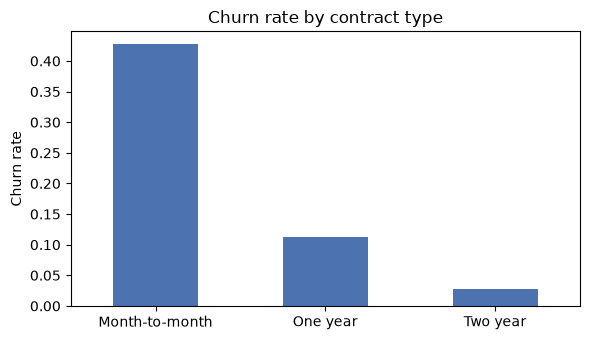

In [8]:
# Churn rate by contract type
churn_by_type = df_join.groupby("Type")["Churn"].mean().sort_values(ascending=False)
print(churn_by_type.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
churn_by_type.plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Churn rate by contract type")
ax.set_xlabel("")
ax.set_ylabel("Churn rate")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "churn_by_contract_type.png"), dpi=120)
plt.show()

The classes are imbalanced (26.5% of customers churned, about 1 churner for every 2.8 active customers), which is why AUC-ROC and recall are used instead of accuracy. Month-to-month customers churn far more often than customers on one- or two-year contracts.

### Converting dates into tenure

In [9]:
# Latest contract start date
df_join['BeginDate'] = pd.to_datetime(df_join['BeginDate'])
begin_max = df_join['BeginDate'].max()

# Start dates of customers who have no charges yet
no_charges_yet = df_join[df_join['TotalCharges'].isna()]['BeginDate'].unique()

# Latest end date
end_max = df_join[df_join['EndDate'] != 'No']['EndDate'].max()

print("Latest start date:", begin_max)
print("Start date of customers without charges:", no_charges_yet)
print("Latest end date:", end_max)

Latest start date: 2020-02-01 00:00:00
Start date of customers without charges: <DatetimeArray>
['2020-02-01 00:00:00']
Length: 1, dtype: datetime64[ns]
Latest end date: 2020-01-01 00:00:00


- The latest contract start date is 2020-02-01.
- Customers without any charges all started on 2020-02-01, so they have not completed their first month yet.
- The latest cancellation date is 2020-01-01, one month earlier.

2020-02-01 is therefore used as the snapshot ("current") date, and `tenure` is the number of days between `BeginDate` and that date.

In [10]:
# Tenure (days) = snapshot date - BeginDate
df, cut_date = df_join.copy(), begin_max
df['tenure'] = cut_date - df['BeginDate']
df['tenure'] = df['tenure'].dt.days.astype(int)

print("Missing tenure values:", df['tenure'].isna().sum())

Missing tenure values: 0


## 4. Preprocessing

### Train / validation / test split (80 / 10 / 10, stratified)

In [11]:
features = df.drop(['customerID', 'Churn', 'EndDate', 'BeginDate'], axis=1).copy()
target = df['Churn']

In [12]:
# First split: train vs. temporary set
train_features, temp_features, train_target, temp_target = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=seed,
    stratify=target
)

# Second split: validation vs. test
valid_features, test_features, valid_target, test_target = train_test_split(
    temp_features,
    temp_target,
    test_size=0.5,
    random_state=seed,
    stratify=temp_target
)

# Work on copies
train_features = train_features.copy()
valid_features = valid_features.copy()
test_features = test_features.copy()

print("Train:", train_features.shape, "Validation:", valid_features.shape, "Test:", test_features.shape)

Train: (5634, 18) Validation: (704, 18) Test: (705, 18)


### One-hot encoding

The encoder is fitted on the training set only and then applied to all three sets.

In [13]:
# Categorical columns
categorical_cols = [
    "Type",
    "PaymentMethod",
    "InternetService",
    "MultipleLines"
]

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
encoder.fit(train_features[categorical_cols])

# Apply one-hot encoding to the three DataFrames
for df in [train_features, valid_features, test_features]:
    encoded = pd.DataFrame(
        encoder.transform(df[categorical_cols]),
        columns=encoder.get_feature_names_out(categorical_cols),
        index=df.index
    )

    df[encoded.columns] = encoded
    df.drop(columns=categorical_cols, inplace=True)

In [14]:
# Columns that still have missing values
train_features.isna().sum()[train_features.isna().sum() > 0]

TotalCharges           8
OnlineSecurity      1224
OnlineBackup        1224
DeviceProtection    1224
TechSupport         1224
StreamingTV         1224
StreamingMovies     1224
dtype: int64

In [15]:
# Missing internet add-ons mean the customer has no internet service -> 0.
# Missing TotalCharges means the customer has not been billed yet -> 0.
for df in [train_features, valid_features, test_features]:
    df[[
        'OnlineSecurity',
        'OnlineBackup',
        'DeviceProtection',
        'TechSupport',
        'StreamingTV',
        'StreamingMovies'
       ]] = df[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']].fillna(0)
    df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [16]:
# Check that no missing values remain
print(train_features.isna().sum()[train_features.isna().sum() > 0])

train_features.info()

Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 4029 to 102
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   PaperlessBilling                         5634 non-null   int64  
 1   MonthlyCharges                           5634 non-null   float64
 2   TotalCharges                             5634 non-null   float64
 3   gender                                   5634 non-null   int64  
 4   SeniorCitizen                            5634 non-null   int64  
 5   Partner                                  5634 non-null   int64  
 6   Dependents                               5634 non-null   int64  
 7   OnlineSecurity                           5634 non-null   float64
 8   OnlineBackup                             5634 non-null   float64
 9   DeviceProtection                         5634 non-null   float64
 10  TechSupport               

### Feature scaling

In [17]:
# Create the scaler
scaler = StandardScaler()

# Numeric columns to scale
scaler_columns = ['MonthlyCharges', 'TotalCharges', 'tenure']

# Fit on train and transform
train_features[scaler_columns] = scaler.fit_transform(
    train_features[scaler_columns]
)

In [18]:
# Transform the validation set
valid_features[scaler_columns] = scaler.transform(
    valid_features[scaler_columns]
)

# Transform the test set
test_features[scaler_columns] = scaler.transform(
    test_features[scaler_columns]
)

## 5. Modeling (baseline, no class balancing)

Helper to plot the ROC curve on the validation set (and optionally the test set).

In [19]:
def auc_roc(
    model,
    val_target=valid_target,
    val_features=valid_features,
    test_target=None,
    test_features=None,
    title="ROC curve"
):

    plt.figure(figsize=(6, 4.5))

    # Validation
    proba = model.predict_proba(val_features)[:, 1]
    score = roc_auc_score(val_target, proba)
    fpr, tpr, _ = roc_curve(val_target, proba)

    plt.plot(fpr, tpr, label=f"Validation (AUC = {score:.4f})")

    # Test (optional)
    if test_target is not None and test_features is not None:
        proba_test = model.predict_proba(test_features)[:, 1]
        score_test = roc_auc_score(test_target, proba_test)
        fpr_test, tpr_test, _ = roc_curve(test_target, proba_test)

        plt.plot(fpr_test, tpr_test, label=f"Test (AUC = {score_test:.4f})")

    # Plot
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend()
    plt.show()

### Logistic Regression

In [20]:
model_1 = LogisticRegression(
    random_state=seed,
    max_iter=1000
)

model_1.fit(train_features, train_target)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1234
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

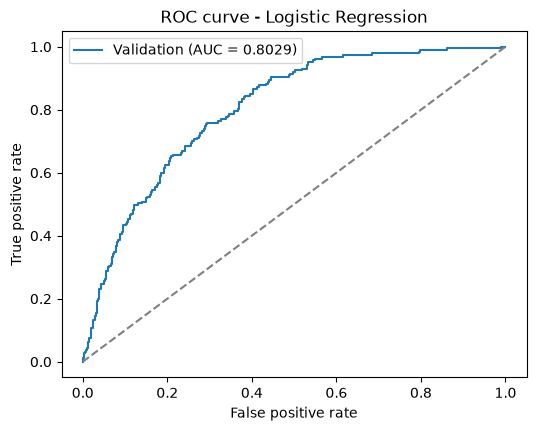

In [21]:
auc_roc(model_1, title="ROC curve - Logistic Regression")

### Random Forest

In [22]:
model_2 = RandomForestClassifier(
    max_depth=10,
    random_state=seed,
)
model_2.fit(
    train_features, train_target
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1234
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

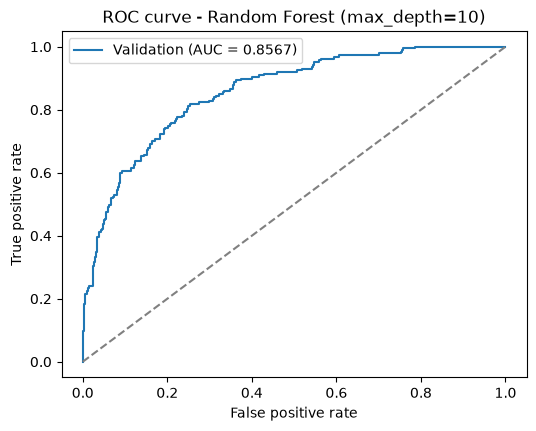

In [23]:
auc_roc(model_2, title="ROC curve - Random Forest (max_depth=10)")

In [24]:
model_3 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=seed
)
model_3.fit(
    train_features, train_target
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

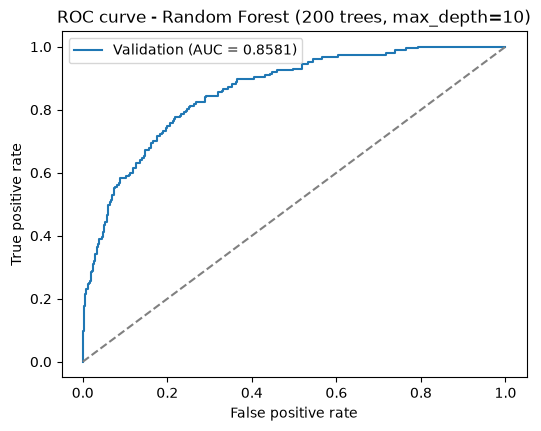

In [25]:
auc_roc(model_3, title="ROC curve - Random Forest (200 trees, max_depth=10)")

In [26]:
model_4 = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=seed
)
model_4.fit(
    train_features, train_target
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

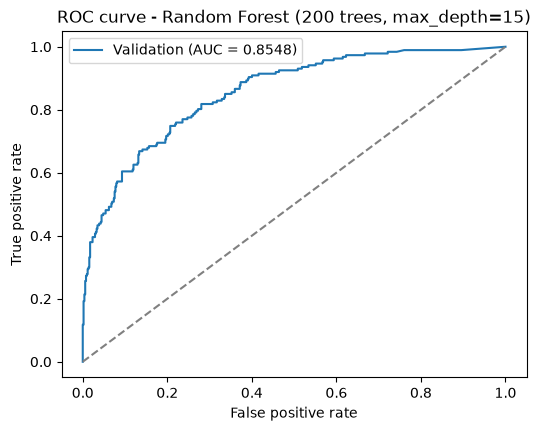

In [27]:
auc_roc(model_4, title="ROC curve - Random Forest (200 trees, max_depth=15)")

### XGBoost

Grid search over depth, number of trees, and learning rate. A combination is only accepted if the gap between train and validation AUC stays below a threshold (to limit overfitting); the search stops early once the target AUC is reached.

In [28]:
def hyper_params_test(
    model,
    train_features,
    train_target,
    val_features,
    val_target,
    depths,
    n_estimators,
    learning_rates,
    dif_threshold,
    objective
):

    best_score = 0
    best_params = None
    best_proba = None
    best_difference = None

    for depth in depths:
        for n in n_estimators:
            for learning in learning_rates:

                clf = model(
                    n_estimators=n,
                    max_depth=depth,
                    learning_rate=learning,
                    random_state=seed,
                    eval_metric="auc"
                )

                clf.fit(train_features, train_target)

                proba = clf.predict_proba(val_features)[:, 1]

                score = roc_auc_score(val_target, proba)
                train_score = roc_auc_score(
                    train_target,
                    clf.predict_proba(train_features)[:, 1]
                )

                difference = train_score - score

                print(
                    f"Params (depth, n_estimators, lr): ({depth}, {n}, {learning})",
                    "| Train AUC:", round(train_score, 4),
                    "| Valid AUC:", round(score, 4),
                    "| Gap:", round(difference, 4)
                )

                if score > best_score and difference <= dif_threshold:
                    best_score = score
                    best_params = (depth, n, learning)
                    best_proba = proba
                    best_difference = difference

                if score >= objective and difference <= dif_threshold:
                    return best_params, best_score, best_proba, best_difference

    return best_params, best_score, best_proba, best_difference

In [29]:
best_params, best_score, best_proba, difference = hyper_params_test(
    XGBClassifier,
    train_features,
    train_target,
    valid_features,
    valid_target,
    depths=[4, 6, 8],
    n_estimators=[300, 600, 900],
    learning_rates=[0.01, 0.1, 0.15],
    dif_threshold=0.05,  # Max allowed train-validation AUC gap (closer to 0 = more consistent)
    objective=0.9        # Stop when this validation AUC is reached
)

print("\nBest parameters:", best_params)
print("Best validation AUC-ROC:", round(best_score, 4))
print("Train-validation gap:", round(difference, 4))

Params (depth, n_estimators, lr): (4, 300, 0.01) | Train AUC: 0.9087 | Valid AUC: 0.8758 | Gap: 0.0329
Params (depth, n_estimators, lr): (4, 300, 0.1) | Train AUC: 0.9845 | Valid AUC: 0.9228 | Gap: 0.0617


Params (depth, n_estimators, lr): (4, 300, 0.15) | Train AUC: 0.9928 | Valid AUC: 0.9284 | Gap: 0.0645


Params (depth, n_estimators, lr): (4, 600, 0.01) | Train AUC: 0.9274 | Valid AUC: 0.8918 | Gap: 0.0356


Params (depth, n_estimators, lr): (4, 600, 0.1) | Train AUC: 0.9967 | Valid AUC: 0.9295 | Gap: 0.0672
Params (depth, n_estimators, lr): (4, 600, 0.15) | Train AUC: 0.9994 | Valid AUC: 0.9291 | Gap: 0.0703


Params (depth, n_estimators, lr): (4, 900, 0.01) | Train AUC: 0.9388 | Valid AUC: 0.9018 | Gap: 0.0369

Best parameters: (4, 900, 0.01)
Best validation AUC-ROC: 0.9018
Train-validation gap: 0.0369


In [30]:
best_params_1, best_score_1, best_proba_1, difference_1 = hyper_params_test(
    XGBClassifier,
    train_features,
    train_target,
    valid_features,
    valid_target,
    depths=[3, 4],
    n_estimators=[1000, 1100, 1200],
    learning_rates=[0.008, 0.009],
    dif_threshold=0.03,  # Max allowed train-validation AUC gap (closer to 0 = more consistent)
    objective=0.9        # Stop when this validation AUC is reached
)

print("\nBest parameters:", best_params_1)
print("Best validation AUC-ROC:", round(best_score_1, 4))
print("Train-validation gap:", round(difference_1, 4))

Params (depth, n_estimators, lr): (3, 1000, 0.008) | Train AUC: 0.9155 | Valid AUC: 0.8884 | Gap: 0.0271


Params (depth, n_estimators, lr): (3, 1000, 0.009) | Train AUC: 0.9191 | Valid AUC: 0.8917 | Gap: 0.0274


Params (depth, n_estimators, lr): (3, 1100, 0.008) | Train AUC: 0.9185 | Valid AUC: 0.891 | Gap: 0.0275


Params (depth, n_estimators, lr): (3, 1100, 0.009) | Train AUC: 0.9219 | Valid AUC: 0.8935 | Gap: 0.0283


Params (depth, n_estimators, lr): (3, 1200, 0.008) | Train AUC: 0.9207 | Valid AUC: 0.8922 | Gap: 0.0285


Params (depth, n_estimators, lr): (3, 1200, 0.009) | Train AUC: 0.9242 | Valid AUC: 0.8955 | Gap: 0.0287


... (2 outputs left out)

Params (depth, n_estimators, lr): (4, 1100, 0.008) | Train AUC: 0.9385 | Valid AUC: 0.9016 | Gap: 0.0369


Params (depth, n_estimators, lr): (4, 1100, 0.009) | Train AUC: 0.9424 | Valid AUC: 0.9042 | Gap: 0.0382


Params (depth, n_estimators, lr): (4, 1200, 0.008) | Train AUC: 0.9414 | Valid AUC: 0.9035 | Gap: 0.0379


Params (depth, n_estimators, lr): (4, 1200, 0.009) | Train AUC: 0.9455 | Valid AUC: 0.9063 | Gap: 0.0392

Best parameters: (3, 1200, 0.009)
Best validation AUC-ROC: 0.8955
Train-validation gap: 0.0287


In [31]:
# Refit the best XGBoost configuration
model_5 = XGBClassifier(
    n_estimators=best_params_1[1],
    max_depth=best_params_1[0],
    learning_rate=best_params_1[2],
    random_state=seed,
    eval_metric="auc"
)
model_5.fit(
    train_features, train_target
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


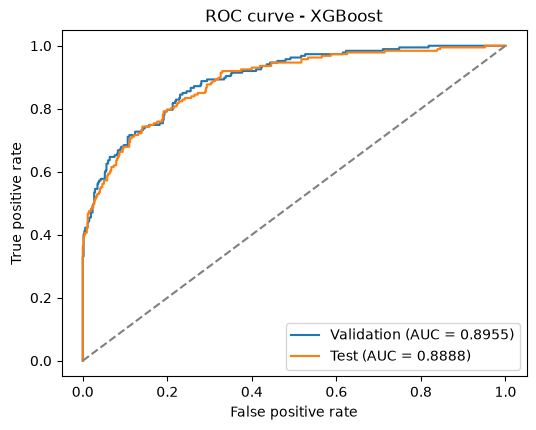

In [32]:
auc_roc(
    model_5,
    test_target=test_target,
    test_features=test_features,
    title="ROC curve - XGBoost"
)

The second, narrower search selects `max_depth=3`, `n_estimators=1200`, `learning_rate=0.009`: validation AUC-ROC **0.8955** with a train–validation gap of 0.0287. The first search reached 0.9018 but with a larger gap (0.0369), so the more conservative configuration is kept.

### Neural network (Keras)

A small fully connected network (16 → 8 → 1) with early stopping on validation AUC.

In [33]:
def nn():
    tf.keras.utils.set_random_seed(seed)  # Seeds Python, NumPy and TensorFlow
    model = Sequential()

    model.add(Input(shape=(train_features.shape[1],)))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(8, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=Adam(learning_rate=0.005),
        loss='binary_crossentropy',
        metrics=[AUC(name='auc')]
    )
    return model

In [34]:
def nn_model_fit(model, class_weight=None):

    early_stop = EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=15,
        restore_best_weights=True
    )

    nn_history = model.fit(
        train_features,
        train_target,
        validation_data=(valid_features, valid_target),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0,
        class_weight=class_weight
    )

    aucroc_score = max(
        nn_history.history['val_auc']
    )

    train_loss, train_auc = model.evaluate(
        train_features, train_target, verbose=0
    )

    valid_loss, valid_auc = model.evaluate(
        valid_features, valid_target, verbose=0
    )

    print("Epochs run:", len(nn_history.history['val_auc']))
    print("Best validation AUC-ROC:", round(aucroc_score, 4))
    print("Train AUC:", round(train_auc, 4))
    print("Valid AUC:", round(valid_auc, 4))
    print("Gap:", round(train_auc - valid_auc, 4))

    return nn_history

In [35]:
model_6 = nn()
nn_history = nn_model_fit(model_6, class_weight=None)

Epochs run: 92
Best validation AUC-ROC: 0.8997
Train AUC: 0.9723
Valid AUC: 0.8997
Gap: 0.0726


## 6. Handling class imbalance

Class weights (`balanced`) are computed from the training target and passed to the same network architecture.

In [36]:
# Class weights
classes = np.unique(train_target)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=np.ravel(train_target)
)

class_weights = dict(zip(classes, weights))

print({int(k): round(float(v), 4) for k, v in class_weights.items()})

{0: 0.6806, 1: 1.8843}


In [37]:
# Same network trained with class weights
model_7 = nn()
nn_model_fit(model_7, class_weight=class_weights);

Epochs run: 100
Best validation AUC-ROC: 0.9125
Train AUC: 0.972
Valid AUC: 0.9125
Gap: 0.0595


In [38]:
# Validation AUC
proba = model_7.predict(valid_features, verbose=0).ravel()
print("Validation AUC:", round(roc_auc_score(valid_target, proba), 4))

Validation AUC: 0.9118


In [39]:
def nn_metrics(model, features=valid_features, target=valid_target):
    proba = model.predict(features, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)

    print(classification_report(target, pred, digits=2))
    print("Confusion matrix:\n", confusion_matrix(target, pred))

In [40]:
print("Neural network WITHOUT class weights (validation)")
nn_metrics(model_6)

Neural network WITHOUT class weights (validation)


              precision    recall  f1-score   support

           0       0.87      0.96      0.92       517
           1       0.86      0.61      0.72       187

    accuracy                           0.87       704
   macro avg       0.87      0.79      0.82       704
weighted avg       0.87      0.87      0.86       704

Confusion matrix:
 [[498  19]
 [ 72 115]]


In [41]:
print("Neural network WITH class weights (validation)")
nn_metrics(model_7)

Neural network WITH class weights (validation)
              precision    recall  f1-score   support

           0       0.93      0.86      0.89       517
           1       0.68      0.81      0.74       187

    accuracy                           0.85       704
   macro avg       0.81      0.84      0.82       704
weighted avg       0.86      0.85      0.85       704

Confusion matrix:
 [[447  70]
 [ 35 152]]


**Effect of class weighting (validation set):**

| | Without class weights | With class weights |
| :--- | :---: | :---: |
| AUC-ROC | 0.8992 | 0.9118 |
| Recall, churn class | 0.61 (115 of 187) | 0.81 (152 of 187) |
| False alarms (active customers flagged) | 19 | 70 |

Class weighting detects 37 more churners in the validation set and improves AUC-ROC, at the cost of more false alarms. Since AUC-ROC is the primary metric and a missed churner is the costliest error, the class-weighted network is selected as the final model.

## 7. Final evaluation

### Model comparison (validation and test AUC-ROC)

Model selection is based on validation AUC; the test set is used only to confirm the result.

In [42]:
models = {
    "Logistic Regression": model_1,
    "Random Forest (depth 10)": model_2,
    "Random Forest (200 trees, depth 10)": model_3,
    "Random Forest (200 trees, depth 15)": model_4,
    "XGBoost": model_5,
    "Neural network": model_6,
    "Neural network + class weights": model_7,
}

def predict_proba_1(model, features):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.predict(features, verbose=0).ravel()

rows = []
for name, model in models.items():
    rows.append({
        "Model": name,
        "Validation AUC": roc_auc_score(valid_target, predict_proba_1(model, valid_features)),
        "Test AUC": roc_auc_score(test_target, predict_proba_1(model, test_features)),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Validation AUC,Test AUC
Model,,
Logistic Regression,0.8029,0.8215
Random Forest (depth 10),0.8567,0.8525
"Random Forest (200 trees, depth 10)",0.8581,0.8537
"Random Forest (200 trees, depth 15)",0.8548,0.8651
XGBoost,0.8955,0.8888
Neural network,0.8992,0.9270
Neural network + class weights,0.9118,0.9099


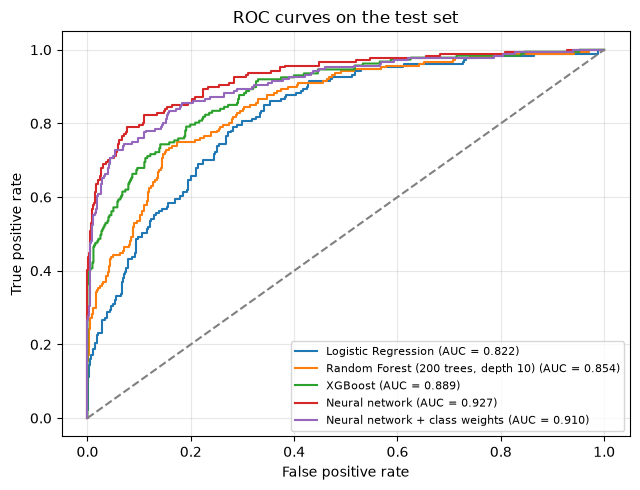

In [43]:
# ROC curves on the test set
plot_models = ["Logistic Regression", "Random Forest (200 trees, depth 10)", "XGBoost",
               "Neural network", "Neural network + class weights"]

fig, ax = plt.subplots(figsize=(6.5, 5))
for name in plot_models:
    proba = predict_proba_1(models[name], test_features)
    fpr, tpr, _ = roc_curve(test_target, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(test_target, proba):.3f})")

ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curves_test.png"), dpi=120)
plt.show()

### Final model: neural network with class weights (test set)

The final model is chosen by validation AUC-ROC: the class-weighted neural network.

In [44]:
final_model = model_7

final_proba = final_model.predict(test_features, verbose=0).ravel()
final_auc = roc_auc_score(test_target, final_proba)

print("Test AUC-ROC:", round(final_auc, 4))

Test AUC-ROC: 0.9099


In [45]:
nn_metrics(final_model, test_features, test_target)  # Final model on the test set

              precision    recall  f1-score   support

           0       0.93      0.83      0.88       518
           1       0.64      0.84      0.72       187

    accuracy                           0.83       705
   macro avg       0.79      0.83      0.80       705
weighted avg       0.86      0.83      0.84       705

Confusion matrix:
 [[428  90]
 [ 30 157]]


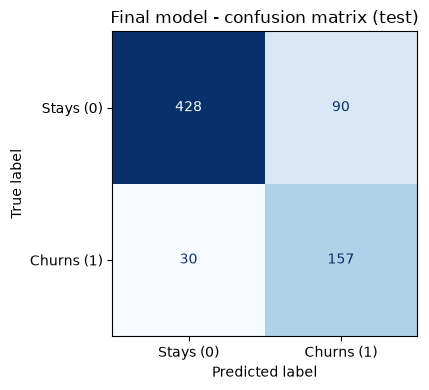

In [46]:
# Confusion matrix of the final model (threshold 0.5)
final_pred = (final_proba >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    test_target, final_pred,
    display_labels=["Stays (0)", "Churns (1)"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Final model - confusion matrix (test)")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "confusion_matrix_final_model.png"), dpi=120)
plt.show()

### Feature importance (XGBoost)

The neural network does not provide feature importances directly, so the XGBoost model (the best tree-based model) is used to see which variables drive churn predictions.

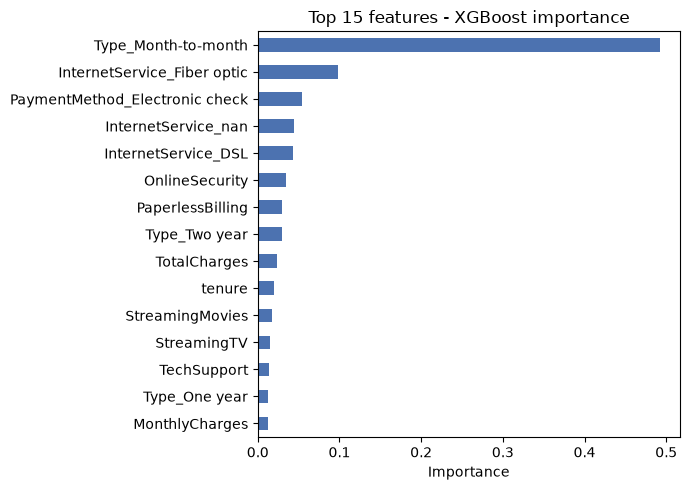

Type_Month-to-month               0.4923
InternetService_Fiber optic       0.0978
PaymentMethod_Electronic check    0.0535
InternetService_nan               0.0445
InternetService_DSL               0.0429
OnlineSecurity                    0.0341
PaperlessBilling                  0.0296
Type_Two year                     0.0295
TotalCharges                      0.0232
tenure                            0.0200
StreamingMovies                   0.0168
StreamingTV                       0.0151
TechSupport                       0.0134
Type_One year                     0.0129
MonthlyCharges                    0.0121
dtype: float32

In [47]:
importance = (
    pd.Series(model_5.feature_importances_, index=train_features.columns)
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(7, 5))
importance.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top 15 features - XGBoost importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "feature_importance_xgboost.png"), dpi=120)
plt.show()

importance.round(4)

## 8. Results summary

| Model | Validation AUC-ROC | Test AUC-ROC |
| :--- | :---: | :---: |
| Logistic Regression | 0.8029 | 0.8215 |
| Random Forest (best variant: 200 trees, depth 10) | 0.8581 | 0.8537 |
| XGBoost (depth 3, 1200 trees, lr 0.009) | 0.8955 | 0.8888 |
| Neural network | 0.8992 | 0.9270 |
| **Neural network + class weights (final)** | **0.9118** | **0.9099** |

**Final model on the test set (705 customers, threshold 0.5):**

- AUC-ROC: **0.9099**
- Recall, churn class: **0.84** (157 of 187 churners detected)
- Precision, churn class: 0.64
- Recall, active class: 0.83 (90 of 518 active customers flagged as false alarms)
- Accuracy: 0.83

Note: the unweighted network scores a higher test AUC (0.9270), but the model is chosen on validation data only; the test set is not used for selection. The original seed (`seed = 1234`) is kept throughout. Results differ from the original course environment because of newer library versions (TensorFlow/Keras weight initialization, and XGBoost, whose grid search now selects 1200 trees).

## 9. Business conclusions

- **What the model delivers:** it detects about **8 out of 10 customers who will churn** (recall 0.84 on the test set), so the marketing team can reach them with retention offers before they cancel.
- **Cost of the trade-off:** about 1 in 3 flagged customers would not have churned (precision 0.64). This is acceptable when a retention offer (discount, plan upgrade) costs much less than losing a customer. If offers are expensive, the decision threshold can be raised to reduce false alarms at the cost of missing more churners.
- **Who churns:** contract type is by far the strongest driver. Month-to-month customers churn at about 43%, versus about 11% for one-year and 3% for two-year contracts. Fiber-optic internet and electronic-check payments are the next most important signals.
- **Recommended actions:** prioritize month-to-month customers flagged by the model, offer incentives to move to one- or two-year contracts, and review the fiber-optic experience (price and service quality).